In [16]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    precision_score,
    recall_score,
    f1_score,
)

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping

In [3]:
df=pd.read_csv("seeds.csv")

In [4]:
df=df.dropna(axis=1, how="all")

In [5]:
df=df.loc[:,~df.columns.str.startswith("Unnamed")]

In [6]:
df.head()

,Area,Perimeter,Compactness,Length of kernel,Width of kernel,Asymmetry coefficient,Length of kernel groove,"Class (1, 2, 3)"
0,15.26,14.84,0.8710,5.763,3.312,2.221,5.220,1
1,14.88,14.57,0.8811,5.554,3.333,1.018,4.956,1
2,14.29,14.09,0.9050,5.291,3.337,2.699,4.825,1
3,13.84,13.94,0.8955,5.324,3.379,2.259,4.805,1
4,16.14,14.99,0.9034,5.658,3.562,1.355,5.175,1


In [7]:
df.tail()

,Area,Perimeter,Compactness,Length of kernel,Width of kernel,Asymmetry coefficient,Length of kernel groove,"Class (1, 2, 3)"
205,12.19,13.20,0.8783,5.137,2.981,3.631,4.870,3
206,11.23,12.88,0.8511,5.140,2.795,4.325,5.003,3
207,13.20,13.66,0.8883,5.236,3.232,8.315,5.056,3
208,11.84,13.21,0.8521,5.175,2.836,3.598,5.044,3
209,12.30,13.34,0.8684,5.243,2.974,5.637,5.063,3


In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 210 entries, 0 to 209
Data columns (total 8 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Area                     210 non-null    float64
 1   Perimeter                210 non-null    float64
 2   Compactness              210 non-null    float64
 3   Length of kernel         210 non-null    float64
 4   Width of kernel          210 non-null    float64
 5   Asymmetry coefficient    210 non-null    float64
 6   Length of kernel groove  210 non-null    float64
 7   Class (1, 2, 3)          210 non-null    int64  
dtypes: float64(7), int64(1)
memory usage: 13.3 KB


In [9]:
df.shape

(210, 8)

In [10]:
df.describe()

,Area,Perimeter,Compactness,Length of kernel,Width of kernel,Asymmetry coefficient,Length of kernel groove,"Class (1, 2, 3)"
count,210.000000,210.000000,210.000000,210.000000,210.000000,210.000000,210.000000,210.000000
mean,14.847524,14.559286,0.870999,5.628533,3.258605,3.700201,5.408071,2.000000
std,2.909699,1.305959,0.023629,0.443063,0.377714,1.503557,0.491480,0.818448
min,10.590000,12.410000,0.808100,4.899000,2.630000,0.765100,4.519000,1.000000
25%,12.270000,13.450000,0.856900,5.262250,2.944000,2.561500,5.045000,1.000000
50%,14.355000,14.320000,0.873450,5.523500,3.237000,3.599000,5.223000,2.000000
75%,17.305000,15.715000,0.887775,5.979750,3.561750,4.768750,5.877000,3.000000
max,21.180000,17.250000,0.918300,6.675000,4.033000,8.456000,6.550000,3.000000


In [11]:
df.dtypes

,0
Area,float64
Perimeter,float64
Compactness,float64
Length of kernel,float64
Width of kernel,float64
Asymmetry coefficient,float64
Length of kernel groove,float64
"Class (1, 2, 3)",int64


In [12]:
df.duplicated()

,0
0,False
1,False
2,False
3,False
4,False
...,...
205,False
206,False
207,False
208,False


In [13]:
df.drop_duplicates()

,Area,Perimeter,Compactness,Length of kernel,Width of kernel,Asymmetry coefficient,Length of kernel groove,"Class (1, 2, 3)"
0,15.26,14.84,0.8710,5.763,3.312,2.221,5.220,1
1,14.88,14.57,0.8811,5.554,3.333,1.018,4.956,1
2,14.29,14.09,0.9050,5.291,3.337,2.699,4.825,1
3,13.84,13.94,0.8955,5.324,3.379,2.259,4.805,1
4,16.14,14.99,0.9034,5.658,3.562,1.355,5.175,1
...,...,...,...,...,...,...,...,...
205,12.19,13.20,0.8783,5.137,2.981,3.631,4.870,3
206,11.23,12.88,0.8511,5.140,2.795,4.325,5.003,3
207,13.20,13.66,0.8883,5.236,3.232,8.315,5.056,3
208,11.84,13.21,0.8521,5.175,2.836,3.598,5.044,3


In [14]:
df.isnull().sum()

,0
Area,0
Perimeter,0
Compactness,0
Length of kernel,0
Width of kernel,0
Asymmetry coefficient,0
Length of kernel groove,0
"Class (1, 2, 3)",0


### Visualisation

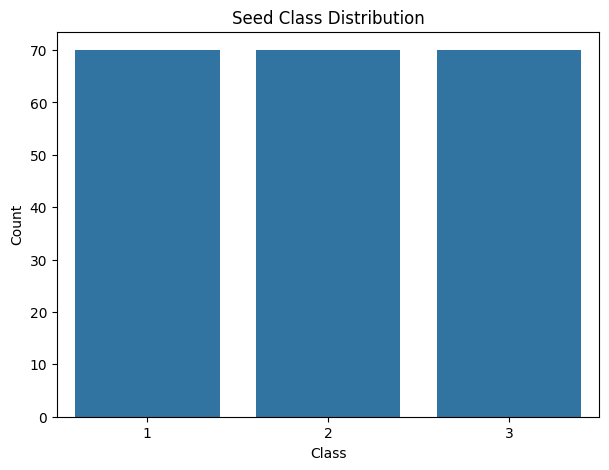

In [17]:
plt.figure(figsize=(7,5))

sns.countplot(x="Class (1, 2, 3)", data=df)

plt.title("Seed Class Distribution")
plt.xlabel("Class")
plt.ylabel("Count")

plt.show()

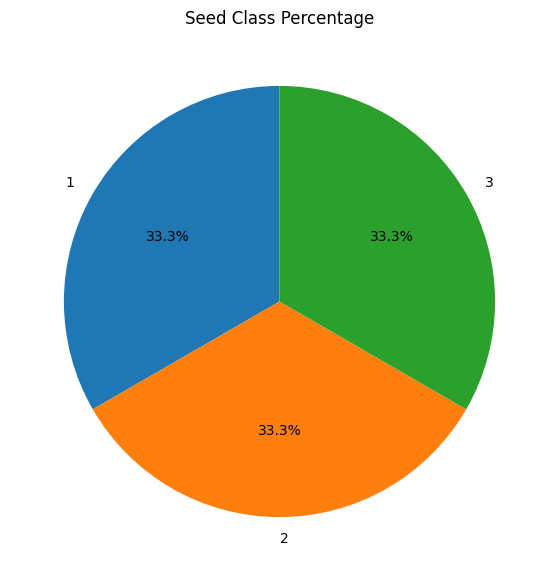

In [18]:
class_counts=df["Class (1, 2, 3)"].value_counts()

plt.figure(figsize=(7,7))

plt.pie(
    class_counts,
    labels=class_counts.index,
    autopct="%.1f%%",
    startangle=90,
    )

plt.title("Seed Class Percentage")

plt.show()

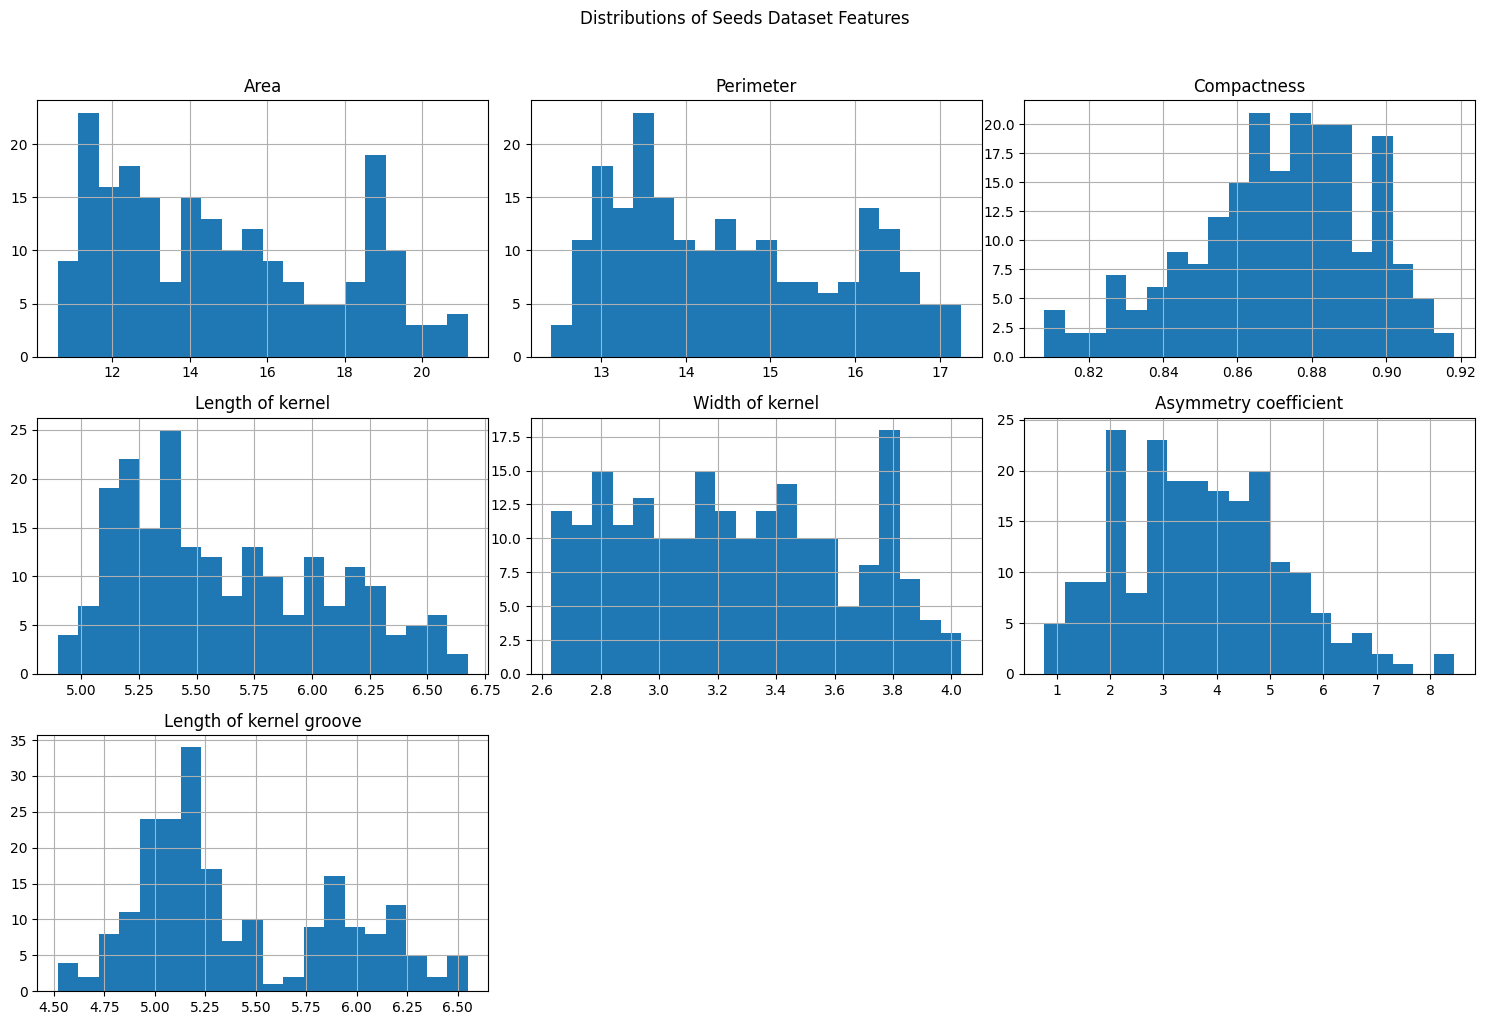

In [19]:
features=df.drop(columns="Class (1, 2, 3)").columns

df[features].hist(figsize=(15,10),bins=20)

plt.suptitle("Distributions of Seeds Dataset Features",y=1.02)

plt.tight_layout()
plt.show()

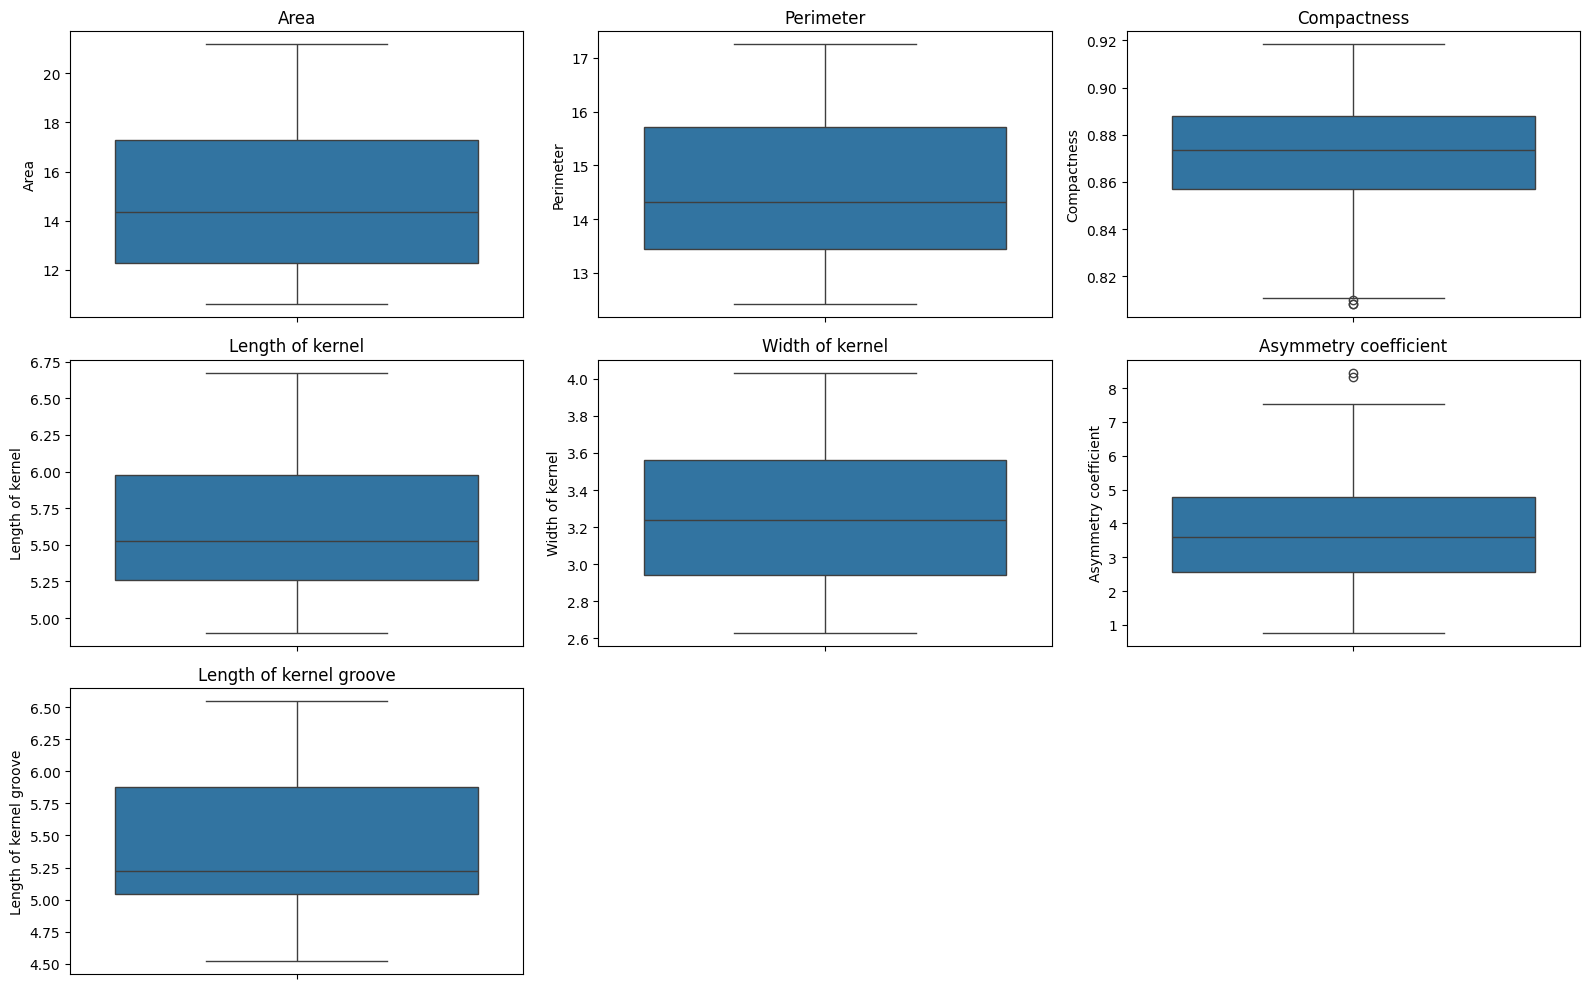

In [20]:
plt.figure(figsize=(16,10))

for i,col in enumerate(features,1):
    plt.subplot(3,3,i)

    sns.boxplot(y=df[col])
    plt.title(col)

plt.tight_layout()
plt.show()

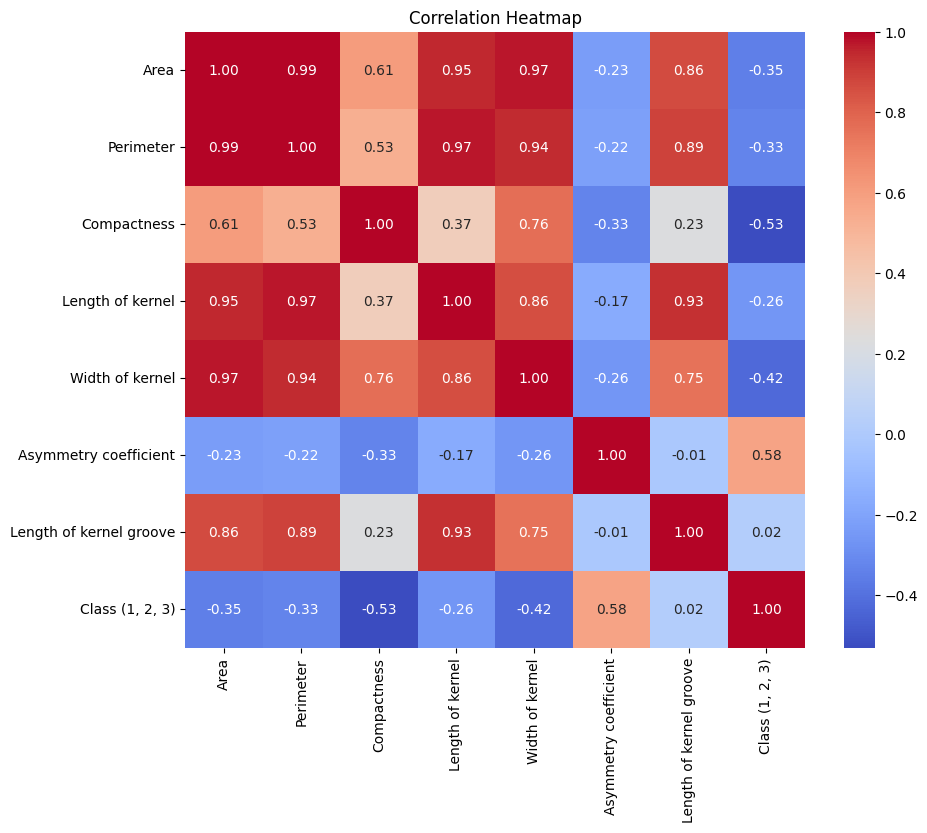

In [21]:
plt.figure(figsize=(10,8))

correlation=df.corr()

sns.heatmap(correlation,
            annot=True,
            cmap="coolwarm",
            fmt=".2f")

plt.title("Correlation Heatmap")

plt.show()

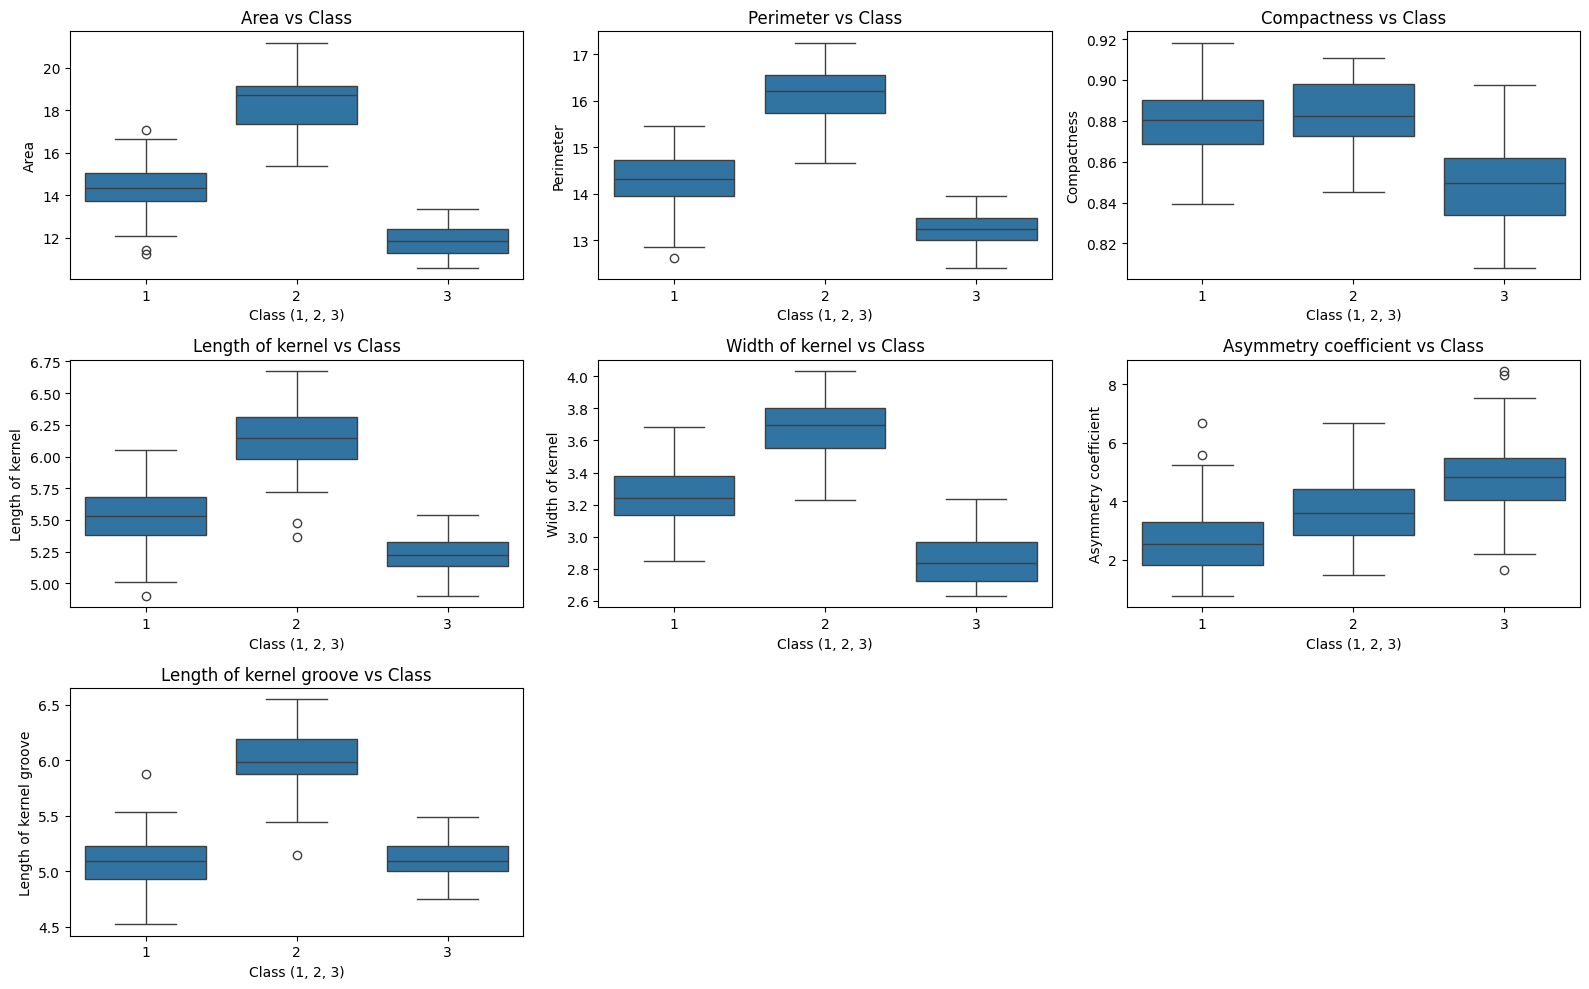

In [22]:
plt.figure(figsize=(16,10))

for i,col in enumerate(features,1):
    plt.subplot(3,3,i)

    sns.boxplot(data=df,x="Class (1, 2, 3)",y=col)
    plt.title(f"{col} vs Class")

plt.tight_layout()
plt.show()

# ANN

In [ ]:
X = df.drop("Class (1, 2, 3)", axis=1)
y_original=df["Class (1, 2, 3)"]

print("input shape:",X.shape)
print("output shape:",y_original.shape)

input shape: (210, 7)
output shape: (210,)


In [ ]:
y=y_original - 1

print("Original classes: ")
print(sorted(y_original.unique()))
print("\n ANN encoded classes: ")
print(y.unique())

Original classes: 
[np.int64(1), np.int64(2), np.int64(3)]

 ANN encoded classes: 
[0 1 2]


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42,stratify=y)

print("Training samples: ", X_train.shape[0])
print("Testing samples: ", X_test.shape[0])

Training samples:  168
Testing samples:  42


In [ ]:

scaler= StandardScaler()
X_train=scaler.fit_transform(X_train)
X_test=scaler.transform(X_test)

In [ ]:
print("First 5 rows of scaled training samples:")
print(X_train[:5])

First 5 rows of scaled training samples:
[[-1.17682401 -1.1750583  -1.02169157 -1.02785725 -1.35751947  1.43188942
  -0.82441016]
 [-0.87298429 -1.06714618  0.86676795 -1.26492983 -0.59897345 -0.3056117
  -1.63150367]
 [-0.12719589  0.01968295 -0.66917913  0.25096694 -0.40933695 -1.4432301
   0.1615857 ]
 [-1.29421662 -1.37546651 -0.66498255 -1.41310019 -1.26136575  1.7668294
  -0.72886004]
 [-0.58295547 -0.70486981  0.69890488 -0.90020279 -0.09149548  3.02743357
  -0.71462918]]


In [ ]:
model = Sequential(
    [
        Input(shape=(7,)),
        Dense(16, activation="relu"),
        Dense(8, activation="relu"),
        Dense(3, activation="softmax"),
    ]
)

In [ ]:
model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_9 (Dense)                 │ (None, 16)             │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 3)              │            27 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 291 (1.14 KB)

 Trainable params: 291 (1.14 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model.compile(
    loss="sparse_categorical_crossentropy",
    optimizer=Adam(learning_rate=0.001),
    metrics=["accuracy"],
)

In [ ]:
loss="sparse_categorical_crossentropy"

In [ ]:
early_stop=EarlyStopping(
                        monitor="val_loss",
                         patience=10,
                         restore_best_weights=True
                        )

In [ ]:
history=model.fit(
    X_train,
    y_train,
    validation_split=0.2,
    batch_size=32,
    epochs=100,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 3s 117ms/step - accuracy: 0.3209 - loss: 1.2023 - val_accuracy: 0.4706 - val_loss: 1.1562
Epoch 2/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - accuracy: 0.3284 - loss: 1.1452 - val_accuracy: 0.4706 - val_loss: 1.1088
Epoch 3/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - accuracy: 0.3284 - loss: 1.0982 - val_accuracy: 0.4706 - val_loss: 1.0639
Epoch 4/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step - accuracy: 0.3358 - loss: 1.0562 - val_accuracy: 0.4706 - val_loss: 1.0210
Epoch 5/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.3284 - loss: 1.0160 - val_accuracy: 0.5000 - val_loss: 0.9828
Epoch 6/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step - accuracy: 0.3358 - loss: 0.9812 - val_accuracy: 0.5000 - val_loss: 0.9458
Epoch 7/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step - accuracy: 0.3657 - loss: 0.9474 - val_accuracy: 0.5294 - val_loss: 0.9114
Epoch 8/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - accuracy: 0.4254 - loss: 0.9161 - val_accuracy: 0.6176 - val_loss

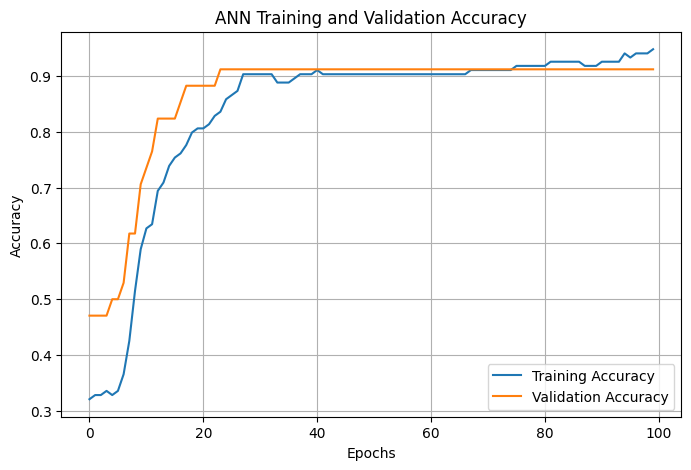

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

plt.plot(history.history["accuracy"],label="Training Accuracy")
plt.plot(history.history["val_accuracy"],label="Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.title("ANN Training and Validation Accuracy")
plt.legend()
plt.grid(True)
plt.show()

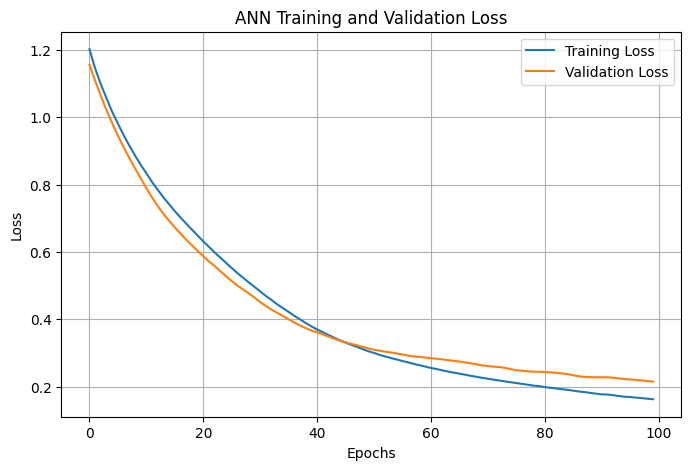

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

plt.plot(history.history["loss"],label="Training Loss")
plt.plot(history.history["val_loss"],label="Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("ANN Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
test_loss, test_accuracy = model.evaluate(X_test, y_test, verbose=1)
print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - accuracy: 0.8571 - loss: 0.3137
Test Loss: 0.31374621391296387
Test Accuracy: 0.8571428656578064


In [ ]:
y_prob=model.predict(X_test,verbose=1)
print(y_prob[:5])

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 106ms/step
[[9.5984799e-01 1.5142341e-03 3.8637761e-02]
 [8.8146806e-02 3.6712244e-04 9.1148615e-01]
 [2.3899831e-01 6.7448276e-01 8.6518906e-02]
 [1.3788310e-02 4.5973916e-06 9.8620713e-01]
 [1.4008718e-02 9.8184437e-01 4.1468339e-03]]


In [ ]:
y_pred=np.argmax(y_prob,axis=1)
print("predicted encoded classes")
print(y_pred[:10])

predicted encoded classes
[0 2 1 2 1 2 1 1 1 1]


In [ ]:
y_pred_original=y_pred+1
y_test_original=y_test+1

print("Predicted classes:")
print(y_pred_original[:10])


Predicted classes:
[1 3 2 3 2 3 2 2 2 2]


In [ ]:
comparison= pd.DataFrame({"Actual Class": y_test_original.values, "Predicted Class": y_pred_original})
comparison.head(10)

,Actual Class,Predicted Class
0,1,1
1,3,3
2,2,2
3,3,3
4,2,2
5,3,3
6,2,2
7,1,2
8,2,2
9,2,2


In [ ]:
accuracy= accuracy_score(y_test_original,y_pred_original)
print("Accuracy:",accuracy)

Accuracy: 0.8571428571428571


In [ ]:
precision= precision_score(y_test_original,y_pred_original,average="weighted")
print("Precision:",precision)

Precision: 0.8823529411764707


In [ ]:
recall= recall_score(y_test_original,y_pred_original,average="weighted")
print("Recall:",recall)

Recall: 0.8571428571428571


In [ ]:
f1= f1_score(y_test_original,y_pred_original,average="weighted")
print("F1 Score:",f1)

F1 Score: 0.8445747800586509


In [ ]:
print(classification_report(y_test_original,y_pred_original))

              precision    recall  f1-score   support

           1       1.00      0.57      0.73        14
           2       0.82      1.00      0.90        14
           3       0.82      1.00      0.90        14

    accuracy                           0.86        42
   macro avg       0.88      0.86      0.84        42
weighted avg       0.88      0.86      0.84        42



In [ ]:
cm=confusion_matrix(y_test_original,y_pred_original)
print(cm)

[[ 8  3  3]
 [ 0 14  0]
 [ 0  0 14]]
